In [1]:
%pip install -q --upgrade pip setuptools wheel
%pip install -q --only-binary=:all: "underthesea==9.5.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 42.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import csv
import re
import html
import time
import zipfile
import warnings
import unicodedata

from pathlib import Path
from functools import lru_cache
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

from underthesea import sent_tokenize, word_tokenize, ner

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

SEED = 42
ALPHA = 1.0
LABELS = ["negative", "neutral", "positive"]

# Dataset archive.zip không có file mô tả nhãn.
# Có thể đổi mapping tại đây nếu nguồn Kaggle của bạn quy định khác.
ARCHIVE_LABEL_MAP = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

# "majority_aspect":
#   lấy polarity xuất hiện nhiều nhất trong nhãn khía cạnh;
#   nếu hòa hoặc chỉ có OTHERS thì dùng số sao.
#
# "stars":
#   1–2 sao = negative, 3 sao = neutral, 4–5 sao = positive.
UIT_TARGET_MODE = "majority_aspect"

# True: xóa tên người bằng NER. Bước này làm preprocessing chậm hơn.
REMOVE_PERSON_NAMES = True

np.random.seed(SEED)

In [3]:
INPUT_ROOT = Path("/kaggle/input")


def collect_csv_sources(root):
    sources = []

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() == ".csv":
            sources.append({
                "source": str(path),
                "member": path.name,
                "data": path.read_bytes()
            })

        elif path.suffix.lower() == ".zip":
            try:
                with zipfile.ZipFile(path) as zf:
                    for member in zf.namelist():
                        if member.lower().endswith(".csv"):
                            sources.append({
                                "source": f"{path}::{member}",
                                "member": member,
                                "data": zf.read(member)
                            })
            except zipfile.BadZipFile:
                pass

    return sources


def first_csv_row(blob):
    text = blob.decode("utf-8-sig", errors="replace")
    return next(csv.reader(io.StringIO(text)))


all_sources = collect_csv_sources(INPUT_ROOT)

archive_candidates = []
uit_candidates = []

for source in all_sources:
    first_row = first_csv_row(source["data"])
    header = {str(x).strip().lower() for x in first_row}

    if {"comment", "n_star", "label"}.issubset(header):
        uit_candidates.append(source)

    elif (
        len(first_row) == 2
        and str(first_row[0]).strip() in {"0", "1", "2"}
    ):
        archive_candidates.append(source)


if not archive_candidates:
    raise FileNotFoundError(
        "Không tìm thấy CSV 2 cột của archive.zip trong /kaggle/input."
    )

if not uit_candidates:
    raise FileNotFoundError(
        "Không tìm thấy Train/Dev/Test của UIT-ViSFD trong /kaggle/input."
    )


# Chọn candidate lớn nhất nếu Kaggle chứa cả ZIP và bản đã giải nén.
archive_source = max(
    archive_candidates,
    key=lambda item: len(item["data"])
)

df_archive_raw = pd.read_csv(
    io.BytesIO(archive_source["data"]),
    header=None,
    names=["label_raw", "text"],
    encoding="utf-8-sig"
)


def get_uit_split(split_name):
    candidates = [
        item for item in uit_candidates
        if Path(item["member"]).name.lower() == f"{split_name.lower()}.csv"
    ]

    if not candidates:
        raise FileNotFoundError(f"Không tìm thấy {split_name}.csv của UIT-ViSFD.")

    selected = max(candidates, key=lambda item: len(item["data"]))

    return pd.read_csv(
        io.BytesIO(selected["data"]),
        encoding="utf-8-sig"
    ), selected["source"]


df_uit_train_raw, uit_train_source = get_uit_split("Train")
df_uit_dev_raw, uit_dev_source = get_uit_split("Dev")
df_uit_test_raw, uit_test_source = get_uit_split("Test")

print("Nguồn archive:", archive_source["source"])
print("Nguồn UIT Train:", uit_train_source)
print("Nguồn UIT Dev:", uit_dev_source)
print("Nguồn UIT Test:", uit_test_source)

print("\nKích thước dữ liệu:")
print("archive:", df_archive_raw.shape)
print("UIT Train:", df_uit_train_raw.shape)
print("UIT Dev:", df_uit_dev_raw.shape)
print("UIT Test:", df_uit_test_raw.shape)

display(df_archive_raw.head())
display(df_uit_train_raw.head())

Nguồn archive: /kaggle/input/datasets/tuannguyenvananh/vietnamese-text-classification-dataset/train.csv
Nguồn UIT Train: /kaggle/input/datasets/minhkhoathi/uit-visfd/Train.csv
Nguồn UIT Dev: /kaggle/input/datasets/minhkhoathi/uit-visfd/Dev.csv
Nguồn UIT Test: /kaggle/input/datasets/minhkhoathi/uit-visfd/Test.csv

Kích thước dữ liệu:
archive: (3040, 2)
UIT Train: (7786, 5)
UIT Dev: (1112, 5)
UIT Test: (2224, 5)


,label_raw,text
0,0,máy dùng hay bị đơ máy
1,0,chỉ có dây cáp nguồn không có adapter sao sử d...
2,0,Chất lượng quá kém Mới dùng được 2 ngày loa ba...
3,0,Usb tôi vừa mới nhận usb này Rất bực bội vì cá...
4,2,Tuyệt vời. Hàng FPT cửa hàng


,index,comment,n_star,date_time,label
0,0,Mới mua máy này Tại thegioididong thốt nốt cảm...,5,2 tuần trước,{CAMERA#Positive};{FEATURES#Positive};{BATTERY...
1,1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạ...,5,14/09/2019,{BATTERY#Negative};{GENERAL#Positive};{OTHERS};
2,2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nh...,3,17/08/2020,{FEATURES#Negative};
3,3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tố...",3,29/02/2020,{FEATURES#Negative};{BATTERY#Neutral};{GENERAL...
4,4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sà...",5,4/6/2020,{BATTERY#Positive};{PERFORMANCE#Positive};{SER...


In [4]:
def star_to_sentiment(value):
    star = int(float(value))

    if star <= 2:
        return "negative"
    elif star == 3:
        return "neutral"
    else:
        return "positive"


def get_uit_sentiment(row):
    if UIT_TARGET_MODE == "stars":
        return star_to_sentiment(row["n_star"])

    polarities = re.findall(
        r"#(Positive|Negative|Neutral)",
        str(row["label"]),
        flags=re.IGNORECASE
    )
    polarities = [p.lower() for p in polarities]

    if polarities:
        counts = Counter(polarities)
        highest_count = max(counts.values())
        winners = [
            label for label, count in counts.items()
            if count == highest_count
        ]

        # Chỉ có một polarity chiếm đa số.
        if len(winners) == 1:
            return winners[0]

    # Hòa giữa các polarity hoặc chỉ có {OTHERS}.
    return star_to_sentiment(row["n_star"])


def clean_pairs(df):
    result = df[["text", "sentiment"]].copy()
    result = result.dropna(subset=["text", "sentiment"])

    result["text"] = (
        result["text"]
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    result = result[
        result["text"].ne("")
        & result["sentiment"].isin(LABELS)
    ]

    # Không để cùng một văn bản xuất hiện nhiều lần.
    result = result.drop_duplicates(subset=["text"], keep="first")

    return result.reset_index(drop=True)


# Dataset archive
archive = df_archive_raw.copy()
archive["label_raw"] = pd.to_numeric(
    archive["label_raw"],
    errors="coerce"
).astype("Int64")

archive["sentiment"] = archive["label_raw"].map(ARCHIVE_LABEL_MAP)
archive = clean_pairs(archive)

archive_train, archive_test = train_test_split(
    archive,
    test_size=0.20,
    random_state=SEED,
    stratify=archive["sentiment"]
)

archive_train = archive_train.reset_index(drop=True)
archive_test = archive_test.reset_index(drop=True)


# Dataset UIT-ViSFD
def prepare_uit_frame(df):
    result = df.copy()
    result = result.rename(columns={"comment": "text"})
    result["sentiment"] = result.apply(get_uit_sentiment, axis=1)
    return clean_pairs(result)


uit_train = pd.concat(
    [
        prepare_uit_frame(df_uit_train_raw),
        prepare_uit_frame(df_uit_dev_raw)
    ],
    ignore_index=True
)

uit_train = uit_train.drop_duplicates(
    subset=["text"],
    keep="first"
).reset_index(drop=True)

uit_test = prepare_uit_frame(df_uit_test_raw)

# Loại các văn bản test trùng hoàn toàn với train.
train_text_set = set(uit_train["text"])
overlap_count = uit_test["text"].isin(train_text_set).sum()

uit_test = (
    uit_test.loc[~uit_test["text"].isin(train_text_set)]
    .reset_index(drop=True)
)

print("Số mẫu UIT test trùng train đã loại:", overlap_count)


def show_distribution(name, train_df, test_df):
    distribution = pd.concat(
        [
            train_df["sentiment"].value_counts().rename("train"),
            test_df["sentiment"].value_counts().rename("test")
        ],
        axis=1
    ).reindex(LABELS).fillna(0).astype(int)

    print(f"\n{name}")
    display(distribution)


show_distribution("archive", archive_train, archive_test)
show_distribution("UIT-ViSFD", uit_train, uit_test)

Số mẫu UIT test trùng train đã loại: 5

archive


,train,test
sentiment,,
negative,872,218
neutral,693,174
positive,833,208



UIT-ViSFD


,train,test
sentiment,,
negative,3102,821
neutral,594,140
positive,5196,1258


In [5]:
STOPWORDS = set("""
à ạ ừ ờ ơi
và hoặc nhưng
là của có cho với trong trên dưới tại từ đến về
một những các cái con chiếc
này đó kia ấy
thì mà khi lúc nếu vì nên bởi do
cũng đều lại vẫn đang đã sẽ
tôi tao mình bạn anh chị em chúng_tôi chúng_ta họ nó
đây đấy
""".split())

# Không xóa các từ phủ định như:
# không, chưa, chẳng, chả, đừng
NEGATIONS = {"không", "chưa", "chẳng", "chả", "đừng"}

SLANG_MAP = {
    "k": "không",
    "ko": "không",
    "khong": "không",
    "kg": "không",
    "khum": "không",
    "hok": "không",
    "hông": "không",
    "dc": "được",
    "đc": "được",
    "được": "được",
    "sp": "sản_phẩm",
    "sanpham": "sản_phẩm",
    "nv": "nhân_viên",
    "dt": "điện_thoại",
    "đt": "điện_thoại",
    "shop": "cửa_hàng",
    "okie": "ok",
    "oke": "ok",
    "okela": "ok"
}

URL_RE = re.compile(r"(https?://\S+|www\.\S+)", flags=re.IGNORECASE)
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w.-]+\.\w+\b")
MENTION_RE = re.compile(r"@\w+")
HTML_TAG_RE = re.compile(r"<[^>]+>")
NON_WORD_RE = re.compile(r"[^\w\s]", flags=re.UNICODE)
MULTISPACE_RE = re.compile(r"\s+")


def remove_person_names(sentence):
    """Loại các token được NER gắn nhãn tên người PER."""
    if not REMOVE_PERSON_NAMES or not sentence.strip():
        return sentence

    try:
        tagged_tokens = ner(sentence)
        kept_tokens = []

        for item in tagged_tokens:
            token = item[0]
            entity_tag = str(item[3]).upper() if len(item) >= 4 else "O"

            if entity_tag not in {"B-PER", "I-PER"}:
                kept_tokens.append(token)

        return " ".join(kept_tokens)

    except Exception:
        # Nếu NER không xử lý được một câu, giữ câu để không mất dữ liệu.
        return sentence


def vietnamese_stem(token):
    """
    Tiếng Việt không biến đổi hình thái giống tiếng Anh.
    Vì vậy chỉ chuẩn hóa slang và ký tự bị kéo dài.
    """
    token = token.strip("_")
    token = SLANG_MAP.get(token, token)

    # Ví dụ: đẹpppp -> đẹp, tốtttt -> tốt
    token = re.sub(r"(.)\1{2,}", r"\1", token)

    return SLANG_MAP.get(token, token)


@lru_cache(maxsize=None)
def preprocess_text(text):
    text = unicodedata.normalize("NFC", str(text))
    text = html.unescape(text)

    # Xóa URL, email, username/mention và HTML.
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HTML_TAG_RE.sub(" ", text)

    # Tách câu trước khi xóa dấu câu.
    sentences = sent_tokenize(text)
    if not sentences:
        sentences = [text]

    all_tokens = []

    for sentence in sentences:
        # NER cần chữ hoa nên chạy trước lowercase.
        sentence = remove_person_names(sentence)

        sentence = sentence.lower()
        sentence = NON_WORD_RE.sub(" ", sentence)
        sentence = MULTISPACE_RE.sub(" ", sentence).strip()

        if not sentence:
            continue

        tokenized_text = word_tokenize(sentence, format="text")
        tokens = tokenized_text.split()

        for token in tokens:
            token = vietnamese_stem(token)

            if (
                token
                and token not in STOPWORDS
                and len(token) > 1
            ):
                all_tokens.append(token)

    # Thêm đặc trưng phủ định, ví dụ "không tốt" -> "không_tốt".
    enriched_tokens = list(all_tokens)

    for i in range(len(all_tokens) - 1):
        if all_tokens[i] in NEGATIONS:
            enriched_tokens.append(
                f"{all_tokens[i]}_{all_tokens[i + 1]}"
            )

    return " ".join(enriched_tokens)


example = archive_train.iloc[0]["text"]

print("Văn bản gốc:")
print(example)

print("\nCác câu sau sentence tokenization:")
print(sent_tokenize(example))

print("\nSau toàn bộ preprocessing:")
print(preprocess_text(example))

Văn bản gốc:
kém chất lượng mình nói ngắn gọn: mua xong xài đúng 1 ngày hư đang đợi bào hành của Tiki lời khuyên: đừng mua hiệu này

Các câu sau sentence tokenization:
['kém chất lượng mình nói ngắn gọn: mua xong xài đúng 1 ngày hư đang đợi bào hành của Tiki lời khuyên: đừng mua hiệu này']

Sau toàn bộ preprocessing:
kém chất_lượng nói ngắn_gọn mua xong xài đúng ngày hư đợi bào_hành lời khuyên đừng mua hiệu đừng_mua


In [6]:
datasets = {
    "Vietnamese Text Classification Dataset": {
        "train": archive_train.copy(),
        "test": archive_test.copy()
    },
    "UIT-ViSFD": {
        "train": uit_train.copy(),
        "test": uit_test.copy()
    }
}

tqdm.pandas()

for dataset_name, data in datasets.items():
    for split_name in ["train", "test"]:
        frame = data[split_name].copy()

        print(f"Preprocessing {dataset_name} - {split_name}")

        frame["processed"] = frame["text"].progress_apply(
            preprocess_text
        )

        empty_count = frame["processed"].eq("").sum()
        print("Số văn bản rỗng sau preprocessing:", empty_count)

        frame = frame.loc[
            frame["processed"].ne("")
        ].reset_index(drop=True)

        data[split_name] = frame

print("\nVí dụ sau preprocessing:")
display(
    datasets["Vietnamese Text Classification Dataset"]["train"][
        ["text", "processed", "sentiment"]
    ].head()
)

Preprocessing Vietnamese Text Classification Dataset - train


  0%|          | 0/2398 [00:00<?, ?it/s]

Số văn bản rỗng sau preprocessing: 2
Preprocessing Vietnamese Text Classification Dataset - test


  0%|          | 0/600 [00:00<?, ?it/s]

Số văn bản rỗng sau preprocessing: 0
Preprocessing UIT-ViSFD - train


  0%|          | 0/8892 [00:00<?, ?it/s]

Số văn bản rỗng sau preprocessing: 0
Preprocessing UIT-ViSFD - test


  0%|          | 0/2219 [00:00<?, ?it/s]

Số văn bản rỗng sau preprocessing: 0

Ví dụ sau preprocessing:


,text,processed,sentiment
0,kém chất lượng mình nói ngắn gọn: mua xong xài...,kém chất_lượng nói ngắn_gọn mua xong xài đúng ...,negative
1,Nhanh hết pin Không biết phải lỗi hay không Mà...,nhanh hết pin không biết phải lỗi hay không hộ...,neutral
2,4G chạy vi vu Trước đây mình từng mua mấy cục ...,chạy vi_vu trước_đây từng mua mấy cục rồi xài ...,positive
3,Giá rẻ chất lượng tốt dùng văn phòng hợp lý!,giá rẻ chất_lượng tốt dùng văn_phòng hợp_lý,positive
4,"Hàng đã qua sử dụng, màn hình điện thoại đã bị...",hàng qua sử_dụng màn_hình điện_thoại bị thay p...,negative


In [7]:
def train_manual_multinomial_nb(
    train_df,
    text_col="processed",
    label_col="sentiment",
    alpha=1.0
):
    classes = [
        label for label in LABELS
        if label in set(train_df[label_col])
    ]

    document_counts = train_df[label_col].value_counts().to_dict()
    total_documents = len(train_df)

    word_counts = {label: Counter() for label in classes}

    for text, label in zip(
        train_df[text_col],
        train_df[label_col]
    ):
        word_counts[label].update(str(text).split())

    vocabulary = sorted(
        set().union(
            *(set(counter.keys()) for counter in word_counts.values())
        )
    )

    vocabulary_size = len(vocabulary)

    if vocabulary_size == 0:
        raise ValueError("Vocabulary rỗng sau preprocessing.")

    total_words_by_class = {
        label: sum(word_counts[label].values())
        for label in classes
    }

    # Bảng tần số từ
    frequency_table = pd.DataFrame({"word": vocabulary})

    for label in classes:
        frequency_table[f"freq_{label}"] = np.fromiter(
            (word_counts[label].get(word, 0) for word in vocabulary),
            dtype=np.int64,
            count=vocabulary_size
        )

    frequency_columns = [
        f"freq_{label}" for label in classes
    ]
    frequency_table["freq_total"] = (
        frequency_table[frequency_columns].sum(axis=1)
    )

    # Bảng prior và log-prior
    priors = {
        label: document_counts[label] / total_documents
        for label in classes
    }

    log_priors = {
        label: np.log(priors[label])
        for label in classes
    }

    prior_table = pd.DataFrame({
        "class": classes,
        "document_count": [
            document_counts[label] for label in classes
        ],
        "prior": [
            priors[label] for label in classes
        ],
        "log_prior": [
            log_priors[label] for label in classes
        ]
    })

    # Bảng xác suất có điều kiện với Laplace smoothing
    probability_table = frequency_table[["word"]].copy()
    log_probability_lookup = {}

    for label in classes:
        denominator = (
            total_words_by_class[label]
            + alpha * vocabulary_size
        )

        probabilities = (
            frequency_table[f"freq_{label}"].to_numpy(dtype=float)
            + alpha
        ) / denominator

        probability_table[f"prob_{label}"] = probabilities
        probability_table[f"log_prob_{label}"] = np.log(probabilities)

        log_probability_lookup[label] = dict(
            zip(vocabulary, np.log(probabilities))
        )

    # Log-likelihood ratio của từ:
    # > 0: nghiêng positive
    # < 0: nghiêng negative
    if {"positive", "negative"}.issubset(classes):
        probability_table["log_likelihood_pos_vs_neg"] = (
            probability_table["log_prob_positive"]
            - probability_table["log_prob_negative"]
        )

    if {"neutral", "negative"}.issubset(classes):
        probability_table["log_likelihood_neu_vs_neg"] = (
            probability_table["log_prob_neutral"]
            - probability_table["log_prob_negative"]
        )

    model = {
        "classes": classes,
        "alpha": alpha,
        "vocabulary": set(vocabulary),
        "log_prior": log_priors,
        "log_probability": log_probability_lookup,
        "frequency_table": frequency_table,
        "probability_table": probability_table,
        "prior_table": prior_table
    }

    return model


def predict_manual_nb(model, processed_documents):
    predictions = []

    for document in processed_documents:
        document_word_counts = Counter(str(document).split())

        scores = {
            label: model["log_prior"][label]
            for label in model["classes"]
        }

        for word, count in document_word_counts.items():
            # Từ không xuất hiện trong tập train được bỏ qua.
            if word not in model["vocabulary"]:
                continue

            for label in model["classes"]:
                scores[label] += (
                    count
                    * model["log_probability"][label][word]
                )

        predicted_label = max(scores, key=scores.get)
        predictions.append(predicted_label)

    return np.asarray(predictions)


def metric_row(
    dataset_name,
    algorithm,
    y_true,
    y_pred,
    train_seconds,
    predict_seconds
):
    return {
        "dataset": dataset_name,
        "algorithm": algorithm,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0
        ),
        "train_seconds": train_seconds,
        "predict_seconds": predict_seconds
    }

In [8]:
nb_artifacts = {}
results = []
prediction_store = {}

for dataset_name, data in datasets.items():
    train_df = data["train"]
    test_df = data["test"]

    start = time.perf_counter()

    nb_model = train_manual_multinomial_nb(
        train_df,
        alpha=ALPHA
    )

    train_seconds = time.perf_counter() - start

    start = time.perf_counter()

    nb_predictions = predict_manual_nb(
        nb_model,
        test_df["processed"]
    )

    predict_seconds = time.perf_counter() - start

    nb_artifacts[dataset_name] = nb_model

    prediction_store[
        (dataset_name, "Naive Bayes")
    ] = {
        "y_true": test_df["sentiment"].to_numpy(),
        "y_pred": nb_predictions
    }

    results.append(
        metric_row(
            dataset_name,
            "Naive Bayes",
            test_df["sentiment"],
            nb_predictions,
            train_seconds,
            predict_seconds
        )
    )

    print("\n" + "=" * 70)
    print("DATASET:", dataset_name)

    print("\n1. Log prior của từng lớp")
    display(nb_model["prior_table"].round(6))

    print("\n2. Các từ có tần số cao nhất")
    display(
        nb_model["frequency_table"]
        .nlargest(20, "freq_total")
        .reset_index(drop=True)
    )

    probability_table = nb_model["probability_table"]

    print("\n3. Các từ nghiêng positive nhất")
    display(
        probability_table
        .nlargest(15, "log_likelihood_pos_vs_neg")
        [[
            "word",
            "prob_negative",
            "prob_positive",
            "log_prob_negative",
            "log_prob_positive",
            "log_likelihood_pos_vs_neg"
        ]]
        .reset_index(drop=True)
    )

    print("\n4. Các từ nghiêng negative nhất")
    display(
        probability_table
        .nsmallest(15, "log_likelihood_pos_vs_neg")
        [[
            "word",
            "prob_negative",
            "prob_positive",
            "log_prob_negative",
            "log_prob_positive",
            "log_likelihood_pos_vs_neg"
        ]]
        .reset_index(drop=True)
    )


DATASET: Vietnamese Text Classification Dataset

1. Log prior của từng lớp


,class,document_count,prior,log_prior
0,negative,871,0.363523,-1.011914
1,neutral,693,0.289232,-1.240526
2,positive,832,0.347245,-1.057724



2. Các từ có tần số cao nhất


,word,freq_negative,freq_neutral,freq_positive,freq_total
0,không,1099,658,259,2016
1,được,590,387,247,1224
2,hàng,375,313,433,1121
3,tốt,50,224,569,843
4,sản_phẩm,217,180,329,726
5,rất,150,174,398,722
6,mua,262,143,216,621
7,dùng,161,196,250,607
8,giao,184,151,222,557
9,bị,258,197,47,502



3. Các từ nghiêng positive nhất


...

,word,freq_negative,freq_neutral,freq_positive,freq_total
0,không,2947,527,2879,6353
1,máy,2264,377,3441,6082
2,mua,2015,276,2470,4761
3,được,1943,370,1923,4236
4,rất,600,126,3226,3952
5,pin,1030,263,2316,3609
6,dùng,819,171,1559,2549
7,mới,1117,177,1225,2519
8,tốt,179,109,2070,2358
9,quá,1001,127,1156,2284



3. Các từ nghiêng positive nhất


,word,prob_negative,prob_positive,log_prob_negative,log_prob_positive,log_likelihood_pos_vs_neg
0,tuyệt,0.000010,0.000800,-11.474933,-7.131250,4.343683
1,sang_trọng,0.000021,0.000645,-10.781786,-7.345660,3.436126
2,tuyệt_vời,0.000125,0.003157,-8.990026,-5.758201,3.231826
3,game_mượt,0.000010,0.000239,-11.474933,-8.341088,3.133845
4,không_chê,0.000010,0.000231,-11.474933,-8.370941,3.103992
5,xịn,0.000010,0.000231,-11.474933,-8.370941,3.103992
6,mượt_camera,0.000010,0.000217,-11.474933,-8.433461,3.041472
7,mạnh_mẽ,0.000010,0.000189,-11.474933,-8.571611,2.903322
8,chu_đáo,0.000042,0.000758,-10.088638,-7.185317,2.903322
9,siêu,0.000031,0.000519,-10.376321,-7.563383,2.812938



4. Các từ nghiêng negative nhất


,word,prob_negative,prob_positive,log_prob_negative,log_prob_positive,log_likelihood_pos_vs_neg
0,không_vào,0.000280,0.000014,-8.179096,-11.174301,-2.995205
1,danh_bạ,0.000135,0.000007,-8.909983,-11.867448,-2.957465
2,không_xứng_đáng,0.000135,0.000007,-8.909983,-11.867448,-2.957465
3,bực_mình,0.000374,0.000021,-7.891414,-10.768836,-2.877422
4,mờ_mờ,0.000125,0.000007,-8.990026,-11.867448,-2.877422
5,đen_thui,0.000125,0.000007,-8.990026,-11.867448,-2.877422
6,buồn_buồn,0.000114,0.000007,-9.077038,-11.867448,-2.790411
7,k_thể,0.000114,0.000007,-9.077038,-11.867448,-2.790411
8,ah,0.000104,0.000007,-9.172348,-11.867448,-2.695100
9,j7,0.000312,0.000021,-8.073735,-10.768836,-2.695100


In [9]:
svm_artifacts = {}

for dataset_name, data in datasets.items():
    train_df = data["train"]
    test_df = data["test"]

    vectorizer = TfidfVectorizer(
        tokenizer=str.split,
        preprocessor=None,
        token_pattern=None,
        lowercase=False,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        max_features=100_000,
        sublinear_tf=True,
        norm="l2"
    )

    svm_model = LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=SEED,
        max_iter=10_000
    )

    start = time.perf_counter()

    X_train = vectorizer.fit_transform(
        train_df["processed"]
    )

    svm_model.fit(
        X_train,
        train_df["sentiment"]
    )

    train_seconds = time.perf_counter() - start

    start = time.perf_counter()

    X_test = vectorizer.transform(
        test_df["processed"]
    )

    svm_predictions = svm_model.predict(X_test)

    predict_seconds = time.perf_counter() - start

    svm_artifacts[dataset_name] = {
        "vectorizer": vectorizer,
        "model": svm_model
    }

    prediction_store[
        (dataset_name, "SVM")
    ] = {
        "y_true": test_df["sentiment"].to_numpy(),
        "y_pred": svm_predictions
    }

    results.append(
        metric_row(
            dataset_name,
            "SVM",
            test_df["sentiment"],
            svm_predictions,
            train_seconds,
            predict_seconds
        )
    )

    print("\n" + "=" * 70)
    print("DATASET:", dataset_name)
    print("Kích thước vector train:", X_train.shape)
    print("Kích thước vector test:", X_test.shape)
    print("Số đặc trưng TF-IDF:", len(vectorizer.vocabulary_))

    # Minh họa vector TF-IDF của văn bản train đầu tiên
    first_vector = X_train[0]

    if first_vector.nnz > 0:
        top_positions = np.argsort(
            first_vector.data
        )[-10:][::-1]

        feature_names = vectorizer.get_feature_names_out()

        vector_example = pd.DataFrame({
            "feature": feature_names[
                first_vector.indices[top_positions]
            ],
            "tfidf": first_vector.data[top_positions]
        })

        print("\n10 thành phần TF-IDF lớn nhất của mẫu đầu tiên:")
        display(vector_example)


DATASET: Vietnamese Text Classification Dataset
Kích thước vector train: (2396, 7142)
Kích thước vector test: (600, 7142)
Số đặc trưng TF-IDF: 7142

10 thành phần TF-IDF lớn nhất của mẫu đầu tiên:


,feature,tfidf
0,đúng ngày,0.279935
1,bào_hành,0.279935
2,hiệu,0.279935
3,ngày hư,0.269453
4,lời,0.269453
5,đừng mua,0.261323
6,mua xong,0.261323
7,đừng_mua,0.261323
8,kém chất_lượng,0.232597
9,khuyên,0.223810



DATASET: UIT-ViSFD
Kích thước vector train: (8892, 26932)
Kích thước vector test: (2219, 26932)
Số đặc trưng TF-IDF: 26932

10 thành phần TF-IDF lớn nhất của mẫu đầu tiên:


,feature,tfidf
0,giá_thành vừa,0.217542
1,ổn_định giá_thành,0.217542
2,wf_khỏe sóng,0.217542
3,bắt wf_khỏe,0.217542
4,to bắt,0.217542
5,wf_khỏe,0.217542
6,ok bin,0.217542
7,sóng ổn_định,0.210584
8,máy thegioididong,0.210584
9,túi_tiền nhân_viên,0.210584


Bảng so sánh tổng hợp:


,dataset,algorithm,accuracy,macro_f1,weighted_f1,train_seconds,predict_seconds
0,UIT-ViSFD,SVM,0.8571,0.6432,0.8420,0.6816,0.0795
1,UIT-ViSFD,Naive Bayes,0.8297,0.5670,0.8027,0.0976,0.0641
2,Vietnamese Text Classification Dataset,SVM,0.7850,0.7757,0.7837,0.1525,0.0168
3,Vietnamese Text Classification Dataset,Naive Bayes,0.7750,0.7605,0.7696,0.0302,0.0136



DATASET: Vietnamese Text Classification Dataset

Naive Bayes
              precision    recall  f1-score   support

    negative     0.7872    0.8486    0.8168       218
     neutral     0.6806    0.5632    0.6164       174
    positive     0.8235    0.8750    0.8485       208

    accuracy                         0.7750       600
   macro avg     0.7638    0.7623    0.7605       600
weighted avg     0.7689    0.7750    0.7696       600


SVM
              precision    recall  f1-score   support

    negative     0.7941    0.8670    0.8289       218
     neutral     0.6707    0.6322    0.6509       174
    positive     0.8687    0.8269    0.8473       208

    accuracy                         0.7850       600
   macro avg     0.7778    0.7754    0.7757       600
weighted avg     0.7842    0.7850    0.7837       600


DATASET: UIT-ViSFD

Naive Bayes
              precision    recall  f1-score   support

    negative     0.7977    0.8453    0.8208       821
     neutral     0.0000    0.

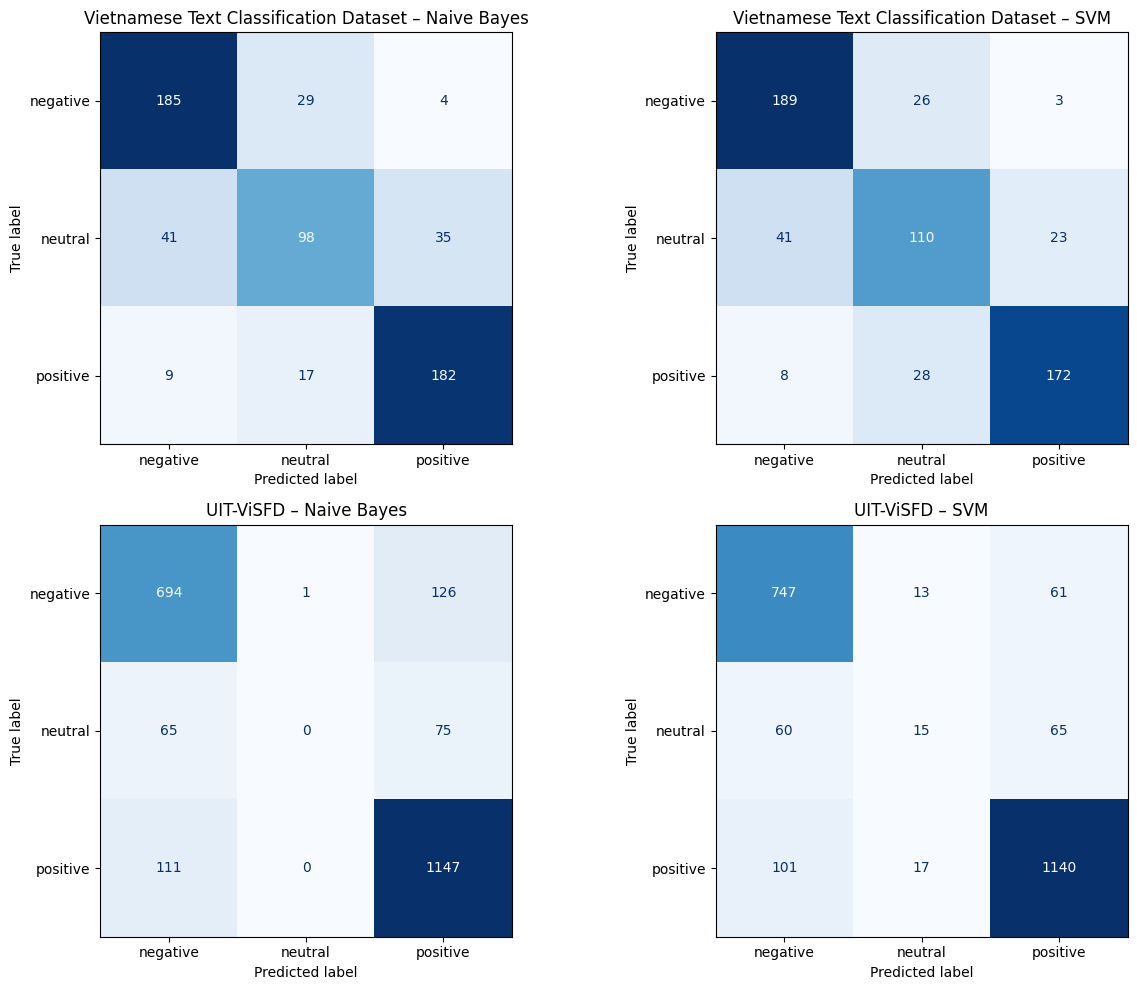

In [10]:
results_df = pd.DataFrame(results).sort_values(
    ["dataset", "macro_f1"],
    ascending=[True, False]
).reset_index(drop=True)

print("Bảng so sánh tổng hợp:")
display(results_df.round(4))


for dataset_name in datasets:
    print("\n" + "=" * 80)
    print("DATASET:", dataset_name)

    for algorithm in ["Naive Bayes", "SVM"]:
        stored = prediction_store[(dataset_name, algorithm)]

        print(f"\n{algorithm}")
        print(
            classification_report(
                stored["y_true"],
                stored["y_pred"],
                labels=LABELS,
                target_names=LABELS,
                digits=4,
                zero_division=0
            )
        )


fig, axes = plt.subplots(
    nrows=len(datasets),
    ncols=2,
    figsize=(13, 5 * len(datasets)),
    squeeze=False
)

for row_index, dataset_name in enumerate(datasets):
    for col_index, algorithm in enumerate(
        ["Naive Bayes", "SVM"]
    ):
        stored = prediction_store[(dataset_name, algorithm)]

        matrix = confusion_matrix(
            stored["y_true"],
            stored["y_pred"],
            labels=LABELS
        )

        display_object = ConfusionMatrixDisplay(
            confusion_matrix=matrix,
            display_labels=LABELS
        )

        display_object.plot(
            ax=axes[row_index, col_index],
            cmap="Blues",
            colorbar=False,
            values_format="d"
        )

        axes[row_index, col_index].set_title(
            f"{dataset_name} – {algorithm}"
        )

plt.tight_layout()
plt.show()

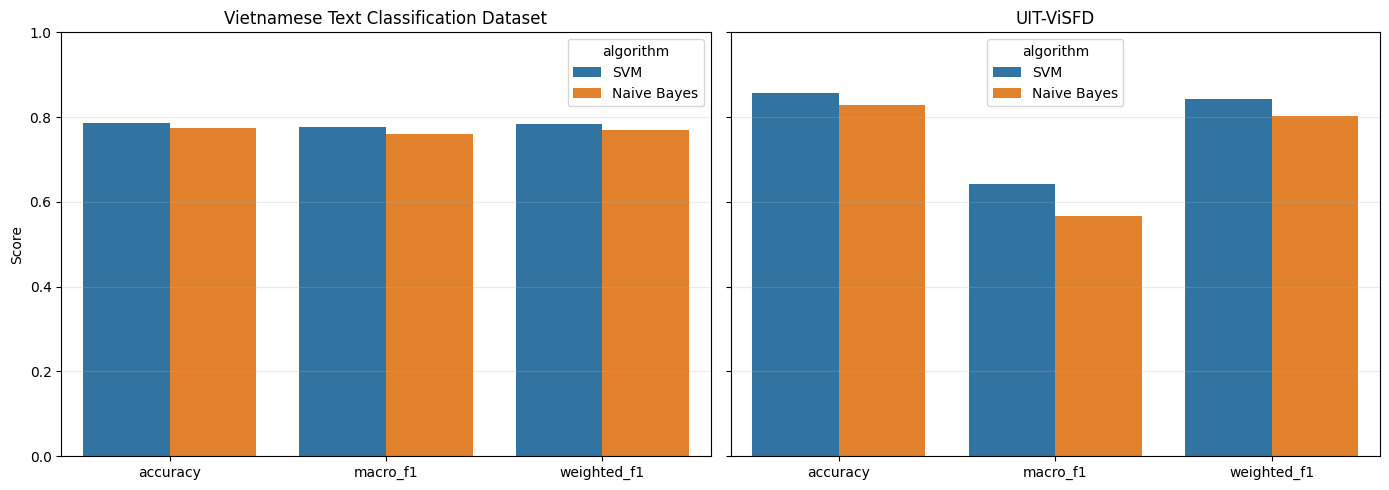

In [11]:
metrics_long = results_df.melt(
    id_vars=["dataset", "algorithm"],
    value_vars=["accuracy", "macro_f1", "weighted_f1"],
    var_name="metric",
    value_name="score"
)

fig, axes = plt.subplots(
    1,
    len(datasets),
    figsize=(14, 5),
    sharey=True
)

if len(datasets) == 1:
    axes = [axes]

for axis, dataset_name in zip(axes, datasets):
    plot_data = metrics_long[
        metrics_long["dataset"] == dataset_name
    ]

    sns.barplot(
        data=plot_data,
        x="metric",
        y="score",
        hue="algorithm",
        ax=axis
    )

    axis.set_title(dataset_name)
    axis.set_ylim(0, 1)
    axis.set_xlabel("")
    axis.set_ylabel("Score")
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [12]:
OUTPUT_DIR = Path("/kaggle/working/sentiment_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

for dataset_name, model in nb_artifacts.items():
    safe_name = (
        dataset_name.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    model["frequency_table"].to_csv(
        OUTPUT_DIR / f"{safe_name}_word_frequency.csv",
        index=False,
        encoding="utf-8-sig"
    )

    model["probability_table"].to_csv(
        OUTPUT_DIR / f"{safe_name}_conditional_probability.csv",
        index=False,
        encoding="utf-8-sig"
    )

    model["prior_table"].to_csv(
        OUTPUT_DIR / f"{safe_name}_class_prior.csv",
        index=False,
        encoding="utf-8-sig"
    )

    prediction_output = datasets[dataset_name]["test"][
        ["text", "processed", "sentiment"]
    ].copy()

    prediction_output["prediction_naive_bayes"] = (
        prediction_store[
            (dataset_name, "Naive Bayes")
        ]["y_pred"]
    )

    prediction_output["prediction_svm"] = (
        prediction_store[
            (dataset_name, "SVM")
        ]["y_pred"]
    )

    prediction_output.to_csv(
        OUTPUT_DIR / f"{safe_name}_test_predictions.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("Các file đã tạo:")

for output_file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(output_file)

Các file đã tạo:
/kaggle/working/sentiment_outputs/model_comparison.csv
/kaggle/working/sentiment_outputs/uit_visfd_class_prior.csv
/kaggle/working/sentiment_outputs/uit_visfd_conditional_probability.csv
/kaggle/working/sentiment_outputs/uit_visfd_test_predictions.csv
/kaggle/working/sentiment_outputs/uit_visfd_word_frequency.csv
/kaggle/working/sentiment_outputs/vietnamese_text_classification_dataset_class_prior.csv
/kaggle/working/sentiment_outputs/vietnamese_text_classification_dataset_conditional_probability.csv
/kaggle/working/sentiment_outputs/vietnamese_text_classification_dataset_test_predictions.csv
/kaggle/working/sentiment_outputs/vietnamese_text_classification_dataset_word_frequency.csv


In [13]:
new_comment = "Máy chạy rất mượt, pin tốt nhưng camera hơi kém"

processed_comment = preprocess_text(new_comment)

print("Văn bản gốc:", new_comment)
print("Sau preprocessing:", processed_comment)

for dataset_name in datasets:
    nb_prediction = predict_manual_nb(
        nb_artifacts[dataset_name],
        [processed_comment]
    )[0]

    vectorizer = svm_artifacts[dataset_name]["vectorizer"]
    svm_model = svm_artifacts[dataset_name]["model"]

    comment_vector = vectorizer.transform(
        [processed_comment]
    )

    svm_prediction = svm_model.predict(
        comment_vector
    )[0]

    print(f"\n{dataset_name}")
    print("Naive Bayes:", nb_prediction)
    print("SVM:", svm_prediction)

Văn bản gốc: Máy chạy rất mượt, pin tốt nhưng camera hơi kém
Sau preprocessing: máy chạy rất mượt_pin tốt camera hơi kém

Vietnamese Text Classification Dataset
Naive Bayes: positive
SVM: neutral

UIT-ViSFD
Naive Bayes: positive
SVM: positive
